# Driven Transmon: Semiclassical Floquet Analysis

## 1. System Hamiltonian and Semiclassical Approximation

Consider a transmon capacitively coupled to a readout resonator. The joint quantum Hamiltonian in the charge basis is given by:
$$\hat{H} = 4 E_C (\hat{n}_t - n_g)^2 - E_J \cos\hat{\varphi}_t + \omega_r \hat{a}^\dagger \hat{a} - i g (\hat{n}_t - n_g)(\hat{a} - \hat{a}^\dagger)$$

where:
* $E_C = e^2 / (2 C_\Sigma)$ is the transmon charging energy,
* $E_J$ is the Josephson coupling energy,
* $n_g$ is the dimensionless offset charge,
* $\hat{n}_t$ and $\hat{\varphi}_t$ are the transmon Cooper-pair number and phase operators satisfying $[\hat{\varphi}_t, \hat{n}_t] = i$,
* $\omega_r$ is the fundamental frequency of the readout resonator,
* $g$ is the capacitive coupling rate between the transmon and the cavity mode.

### External Drive and Semiclassical approximation
To probe or readout the transmon dispersively, a microwave drive at frequency $\omega_d$ is applied through the resonator:
$$\hat{H}_d(t) = -i \varepsilon_d \sin(\omega_d t)(\hat{a} - \hat{a}^\dagger)$$

When the resonator contains a macroscopically populated coherent field, we can perform a time-dependent displacement frame transformation $\hat{a} \to \hat{a} +\alpha(t)$, where $\alpha(t) \approx \sqrt{N_r} e^{-i \omega_d t}$ describes the classical intra-cavity field and $N_r = \langle \hat{a}^\dagger \hat{a} \rangle$ is the mean intra-cavity photon number.

Treating the cavity field classically replaces the quantum resonator degrees of freedom with an effective classical drive coupled directly to the transmon charge operator:
$$\hat{H}(t) = \hat{H}_0 + \hat{H}_d(t) = 4 E_C (\hat{n}_t - n_g)^2 - E_J \cos\hat{\varphi}_t + \Omega_d \cos(\omega_d t) \hat{n}_t$$

The drive amplitude $\Omega_d$ is directly calibrated to the cavity photon population via $\Omega_d = 2 g \sqrt{N_r}$.

---

In [2]:
import qbran as br

import numpy as np
import matplotlib.pyplot as plt

# Circuit definition
# Parameter from Dumas et al. Phys. Rev. X 14, 041023 (2024)
tmon = br.Transmon(EJ=0.22*110, EC=0.22, ng=0.0, ncut=55, truncated_dim=25)
circuit = br.HilbertSpace([tmon])

print(f"Transmon frequency: ω_q/2π =  {tmon.E01:.3f} GHz")
print(f"Transmon anharmonicity: α_q/2π = {tmon.anharmonicity:.3f} GHz")

omega_d = 7.5   # Classical drive frequency
g = 0.12        # Transmon-drive coupling strength
print(f"\nDrive frequency: ω_d/2π =  {omega_d:.3f} GHz")
print(f"Drive coupling: g_d/2π =  {g:.3f} GHz")

n_max = 200 # Maximum photons in the resonator drive
amps_d = np.linspace(0.0, 2*g*np.sqrt(n_max), 200)
Nr = (amps_d / (2 * g))**2

Transmon frequency: ω_q/2π =  6.298 GHz
Transmon anharmonicity: α_q/2π = -0.240 GHz

Drive frequency: ω_d/2π =  7.500 GHz
Drive coupling: g_d/2π =  0.120 GHz


## 2. Floquet Theory

Because the driven Hamiltonian is strictly periodic in time, $\hat{H}(t + T) = \hat{H}(t)$ with period $T = 2\pi / \omega_d$, we employ **Floquet's theorem** (the temporal analogue of Bloch's theorem in spatially periodic lattices).

According to Floquet's theorem, the solutions to the time-dependent Schrödinger equation $i \partial_t |\psi_k(t)\rangle = \hat{H}(t) |\psi_k(t)\rangle$ take the form of stationary Floquet states:
$$|\psi_k(t)\rangle = e^{-i \varepsilon_k t} |\phi_k(t)\rangle$$

where:
* $\varepsilon_k$ are the real **quasienergies**, uniquely defined modulo the drive frequency $\omega_d$ within the first Floquet Brillouin zone: $-\omega_d/2 \le \varepsilon_k \le \omega_d/2$
* $|\phi_k(t)\rangle$ are the **Floquet modes**, which share the periodicity of the Hamiltonian: $|\phi_k(t + T)\rangle = |\phi_k(t)\rangle$

At $t = 0$, the Floquet modes and quasienergies correspond to the eigenstates and phase eigenvalues of the one-period time evolution operator $\hat{U}(T, 0)$:
$$\hat{U}(T, 0) |\phi_k(0)\rangle = e^{-i \varepsilon_k T} |\phi_k(0)\rangle, \quad \text{where} \quad \hat{U}(T, 0) = \mathcal{T} \exp\left(-i \int_0^T \hat{H}(t) \, dt\right)$$

QBrAn provides two complementary numerical frameworks to solve this eigenproblem: the **Propagator method** and the **Shirley (Sambe space) method**.

---

### Propagator Method (Yoshida 4th-Order Splitting)

The propagator approach computes $\hat{U}(T, 0)$ directly by numerically integrating the time evolution operator over a single drive period $T$, followed by a dense diagonalization of $\hat{U}(T, 0)$.

To maintain high numerical precision and preserve unitarity without requiring excessively fine discretization, the library implements a **4th-order symplectic Yoshida integrator**:
1. The drive period $T$ is divided into `nsteps` intervals of length $\Delta t$.
2. Each time step $\Delta t$ is partitioned into three symmetric sub-steps using Yoshida weights $y_1 = 1 / (2 - 2^{1/3})$ and $y_0 = -2^{1/3} y_1$, such that $\Delta t = y_1 \Delta t + y_0 \Delta t + y_1 \Delta t=\delta t_1+\delta t_0+\delta t_1$.
3. Within each interval, $U(t+\Delta t,t)=S_2(\delta t_1)S_2(\delta t_0)S_2(\delta t_1)+\mathcal{O}(\Delta t^5)$, where $S_2(\delta t_j)=e^{-i\hat{H}_0\delta t_j/2}e^{-i\hat{V}\alpha_j}e^{-i\hat{H}_0\delta t_j/2}$ is the split operator with $\hat{V}=\Omega_d\hat{n}_t$ and $\alpha_j=(\sin\omega_d(t+\delta t_j)-\sin\omega_d t)/\omega_d$.

In [42]:
opt = br.Options(nsteps = 20)
analysis = circuit.branch_analysis(kind="propagator", options=opt)
results = analysis.run(omega_d, amps_d)

Branch Analysis: 100%|██████████| 1/1 [00:00<00:00, 10.88it/s]


---

### Shirley Method (Extended Sambe Space)

An alternative to time integration is the **Shirley approach**, which reformulates the time-dependent problem into an equivalent time-independent eigensystem in the extended **Sambe space** $\mathcal{H}_T = \mathcal{H} \otimes \mathcal{L}_2(T)$.

By expanding the periodic Floquet modes in a Fourier series of drive harmonics, $|\phi_k(t)\rangle = \sum_{m=-\infty}^{\infty} |\phi_k^{(m)}\rangle e^{-i m \omega_d t}$, the time-dependent Schrödinger equation transforms into an infinite-dimensional static matrix eigenvalue equation:
$$\sum_n \hat{\mathcal{H}}_{m, n} |\phi_k^{(n)}\rangle = \varepsilon_k |\phi_k^{(m)}\rangle$$

Truncating the Fourier expansion to $m \in [-K, \dots, K]$ yields the **Shirley Floquet Hamiltonian** of dimension $D = (2K + 1) \times \dim(\mathcal{H})$:
$$\hat{\mathcal{H}}_F = \begin{pmatrix}
\ddots & \vdots & \vdots & \vdots & \ddots \\
\dots & \hat{H}_0 - \omega_d \hat{I} & \frac{\Omega_d}{2} \hat{V} & 0 & \dots \\
\dots & \frac{\Omega_d}{2} \hat{V} & \hat{H}_0 & \frac{\Omega_d}{2} \hat{V} & \dots \\
\dots & 0 & \frac{\Omega_d}{2} \hat{V} & \hat{H}_0 + \omega_d \hat{I} & \dots \\
\ddots & \vdots & \vdots & \vdots & \ddots
\end{pmatrix}$$

* **Diagonal blocks** represent the bare system dressed by discrete drive harmonic quanta ($m \omega_d$).
* **Off-diagonal blocks** describe single-photon exchange mediated by the drive operator $\hat{V} = \hat{n}_t$ with coupling strength $\Omega_d / 2$.

In [48]:
opt_shirley = br.Options(K = 20)
analysis_shirley = circuit.branch_analysis(kind="shirley", options=opt_shirley)
results_shirley = analysis_shirley.run(omega_d, amps_d)

Branch Analysis: 100%|██████████| 1/1 [00:28<00:00, 28.51s/it]


#### Computational Comparison:
* **Propagator (`kind="propagator"`)**: Operates strictly within the bare Hilbert space dimension $\dim(\mathcal{H})$. For single-tone drives and sweeps over amplitude, it is generally faster and uses minimal memory.
* **Shirley (`kind="shirley"`)**: Yields Floquet states represented directly in Sambe space, facilitating extraction of period-averaged observables $\langle\langle \hat{O} \rangle\rangle$ and harmonic spectra. Because the matrix is block-tridiagonal, QBrAn exploits sparse solvers (`sparse=True`) to compute the desired spectrum efficiently.

---

## 3. Branch Analysis and State Tracking

As the drive amplitude $\Omega_d$ (or equivalently, the intra-cavity photon number $N_r$) increases, the transmon eigenstates shift and interact under the intense microwave field.

### Adiabatic Branch Tracking
Because numerical eigensolvers order eigenvalues strictly by magnitude, physical levels can become disordered or permuted across amplitude steps. QBrAn implements **adiabatic state tracking** along the amplitude sweep:
1. At zero drive ($\Omega_d = 0$), Floquet states are matched to the bare undriven eigenstates $|i\rangle$ of $\hat{H}_0$.
2. At each consecutive drive step $A_m \to A_{m+1}$, QBrAn computes the eigenvector overlap matrix $M_{i, j} = |\langle \phi_i(A_m) | \phi_j(A_{m+1}) \rangle|$
3. Optimal one-to-one state association is resolved via the linear sum assignment algorithm (`scipy.optimize.linear_sum_assignment(-M)`), ensuring smooth, continuous energy and observable branches.

### Avoided Level Crossings and Multi-Photon Resonances
In the quasienergy spectrum, as drive power increases:
* Energy levels experience power-dependent frequency shifts (**AC Stark shifts**).
* When two levels satisfy a multi-photon resonance condition, $E_j(N_r) - E_i(N_r) \approx m \omega_d\,(m \in \mathbb{Z})$ they undergo an **avoided crossing**.
* Across the avoided crossing, the states exchange energy with the cavity. Monitoring the average transmon excitation number $\langle \hat{N}_t \rangle = \langle \phi_k(t) | \hat{n}_t | \phi_k(t) \rangle$ reveals sharp transitions where low-lying transmon states suddenly acquire significant population in higher excited levels.
* This mechanism underpins **Measurement-Induced State Transitions (MIST)**: driving the readout resonator at high photon numbers $N_r$ can induce resonant transitions that excite or ionize the transmon qubit into highly excited states.

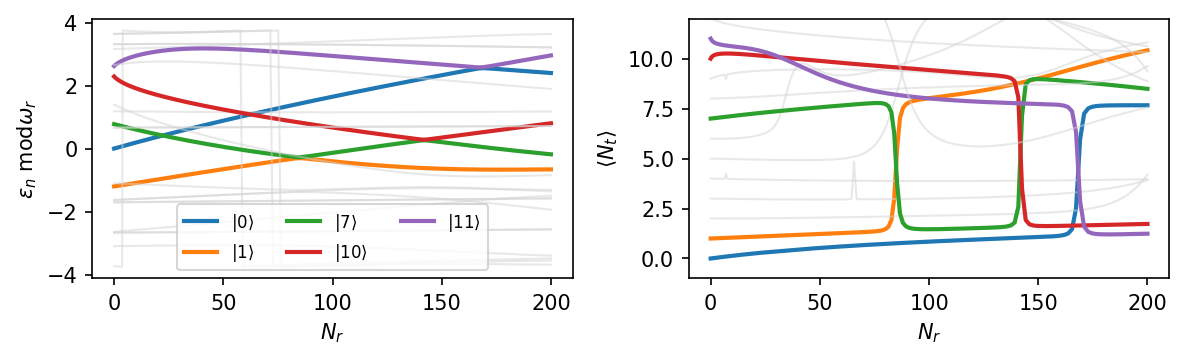

In [43]:
quasienergies   = results.quasienergies[0, :, :]
avg_excitations = results.avg_excitation[0, :, :]

colored = [0, 1, 7, 10, 11]

fig, axs = plt.subplots(1, 2, figsize=(8, 2.5), dpi=150)
for i in range(quasienergies.shape[1]):
    col = f'C{colored.index(i)}' if i in colored else 'lightgray'
    legend = fr'$|{i}\rangle$' if i in colored else None
    alp = 1.0 if i in colored else 0.5
    lw  = 2.0 if i in colored else 1.0
    axs[0].plot(Nr, quasienergies[:, i], color=col, alpha=alp, linewidth=lw, label=legend)
    axs[1].plot(Nr, avg_excitations[:, i], color=col, alpha=alp, linewidth=lw, label=legend)
axs[1].set_ylim(-1, 12)
for i in [0,1]: axs[i].set_xlabel(r'$N_r$')
axs[0].set_ylabel(r'$\epsilon_n$ mod$\omega_r$')
axs[1].set_ylabel(r'$\langle N_t \rangle$')
axs[0].legend(loc='lower center', fontsize=8, ncol=3)
fig.tight_layout()
plt.show()

---

## 4. References

1. **Measurement-Induced State Transitions (MIST)**:
   * M. F. Dumas, et al., *"Measurement-induced transmon ionization"*, [Phys. Rev. X **14**, 041023 (2024)](https://doi.org/10.1103/PhysRevX.14.041023).
2. **Floquet Theory in Superconducting Circuits**:
   * D. K. Weiss, *"Floquet: Identifying nonlinear resonances in quantum systems due to parametric drives"*, GitHub repository: [dkweiss31/floquet](https://github.com/dkweiss31/floquet).
   * Sato, Masahiro, and Tatsuhiko N. Ikeda. *"Floquet theory and applications in open quantum and classical systems."* [Journal of the Physical Society of Japan 94.11 (2025): 111007](https://arxiv.org/abs/2508.01783).
3. **Symplectic Integration**:
   * H. Yoshida, *"Construction of higher order symplectic integrators"*, [Phys. Lett. A **150**, 262 (1990)](https://doi.org/10.1016/0375-9601(90)90092-3).